# Titanic Survival Prediction


## 1. Import Libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


Matplotlib is building the font cache; this may take a moment.


## 2. Load Data


In [2]:
df = pd.read_csv("Titanic.csv")
df.head()


,Unnamed: 0,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 3. Basic Data Analysis


In [3]:
print("Dataset shape:", df.shape)
df.info()


Dataset shape: (891, 16)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Unnamed: 0   891 non-null    int64  
 1   survived     891 non-null    int64  
 2   pclass       891 non-null    int64  
 3   sex          891 non-null    str    
 4   age          714 non-null    float64
 5   sibsp        891 non-null    int64  
 6   parch        891 non-null    int64  
 7   fare         891 non-null    float64
 8   embarked     889 non-null    str    
 9   class        891 non-null    str    
 10  who          891 non-null    str    
 11  adult_male   891 non-null    bool   
 12  deck         203 non-null    str    
 13  embark_town  889 non-null    str    
 14  alive        891 non-null    str    
 15  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(5), str(7)
memory usage: 99.3 KB


## 4. Missing Values


In [4]:
df.isnull().sum()


Unnamed: 0       0
survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

## 5. Survival Count


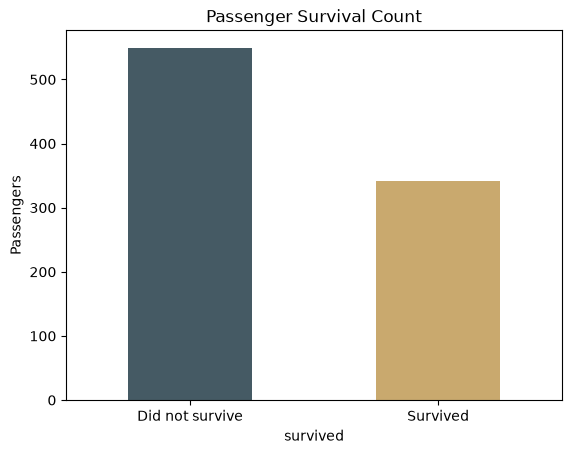

In [5]:
df["survived"].value_counts().sort_index().plot(kind="bar", color=["#455a64", "#c9a96e"])
plt.xticks([0, 1], ["Did not survive", "Survived"], rotation=0)
plt.ylabel("Passengers")
plt.title("Passenger Survival Count")
plt.show()


## 6. Survival by Sex and Class


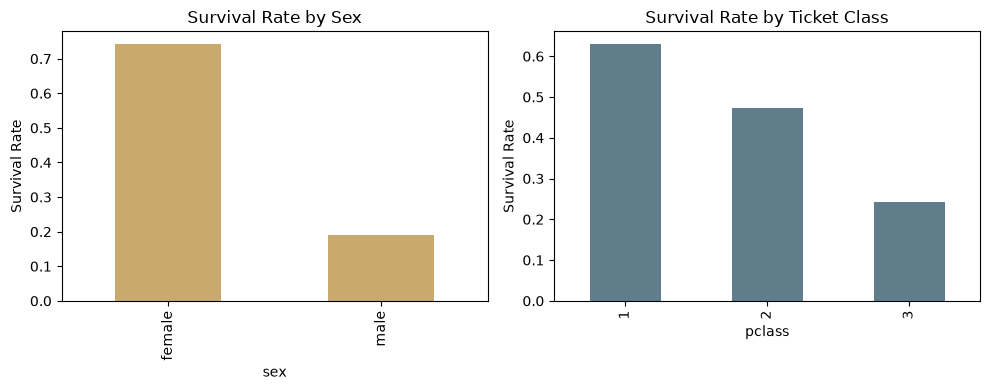

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
df.groupby("sex")["survived"].mean().plot(kind="bar", ax=axes[0], color="#c9a96e")
axes[0].set_title("Survival Rate by Sex")
axes[0].set_ylabel("Survival Rate")
df.groupby("pclass")["survived"].mean().plot(kind="bar", ax=axes[1], color="#607d8b")
axes[1].set_title("Survival Rate by Ticket Class")
axes[1].set_ylabel("Survival Rate")
plt.tight_layout()
plt.show()


## 7. Age Distribution


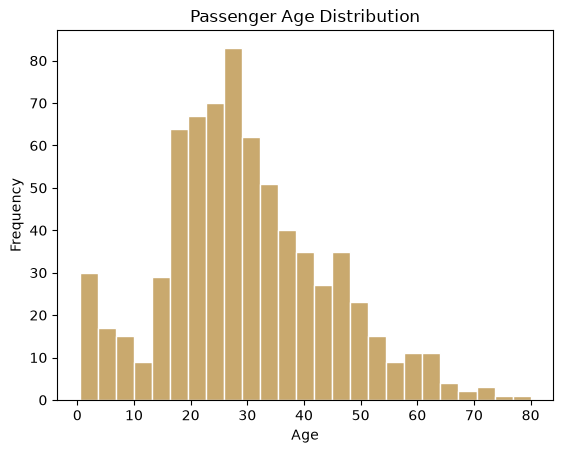

In [7]:
df["age"].dropna().plot(kind="hist", bins=25, color="#c9a96e", edgecolor="white")
plt.xlabel("Age")
plt.title("Passenger Age Distribution")
plt.show()


## 8. Feature Engineering


In [8]:
df["family_size"] = df["sibsp"] + df["parch"] + 1


## 9. Select Features and Target


In [9]:
features = ["pclass", "sex", "age", "family_size", "fare", "embarked"]
X = df[features]
y = df["survived"]


## 10. Split the Data


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


## 11. Prepare the Features


In [11]:
numeric_features = ["pclass", "age", "family_size", "fare"]
categorical_features = ["sex", "embarked"]

numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])

categorical_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, numeric_features),
    ("categories", categorical_steps, categorical_features)
])


## 12. Train the Model


In [12]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=200, random_state=42))
])

model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numbers', ...), ('categories', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different

## 13. Evaluate the Model


Accuracy: 0.804
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       110
           1       0.78      0.68      0.73        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



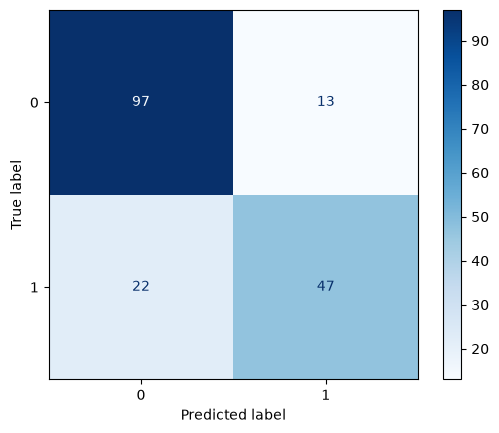

In [13]:
predictions = model.predict(X_test)
print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
print(classification_report(y_test, predictions))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues")
plt.show()


## 14. Train and Save the Final Model


In [14]:
model.fit(X, y)
joblib.dump(model, "titanic_survival_pipeline.joblib")


['titanic_survival_pipeline.joblib']

## 15. Example Prediction


In [15]:
passenger = pd.DataFrame([{
    "pclass": 2,
    "sex": "female",
    "age": 28,
    "family_size": 2,
    "fare": 72.0,
    "embarked": "S"
}])

probability = model.predict_proba(passenger)[0][1]
print("Estimated survival chance:", round(probability * 100, 1), "%")


Estimated survival chance: 100.0 %
